# IDX30 Momentum & Risk Screener

Proyek ini membangun sebuah stock screener untuk 30 saham konstituen IDX30, menggunakan kombinasi tiga kategori indikator:
1. **Momentum** (return 3 bulan & 6 bulan)
2. **Risk-adjusted quality** (volatility, Sharpe ratio, max drawdown)
3. **Liquidity** (rata-rata volume harian)

Setiap metrik dinormalisasi menggunakan percentile rank, lalu digabung menjadi satu composite score dengan bobot:
- Momentum: 40%
- Sharpe Ratio: 35%
- Volatility/Drawdown: 15%
- Liquidity: 10%

Output akhir adalah ranking 30 saham IDX30 berdasarkan composite score tersebut.

## 1. Setup & Data Collection

Import library yang dibutuhkan dan definisikan daftar 30 ticker saham IDX30.

In [18]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# Daftar 30 ticker konstituen IDX30 periode 3 Agustus - 30 Oktober 2026
idx30_tickers = [
    'AADI.JK', 'ADMR.JK', 'ADRO.JK', 'AMRT.JK', 'ANTM.JK',
    'ASII.JK', 'BBCA.JK', 'BBNI.JK', 'BBRI.JK', 'BMRI.JK',
    'BRPT.JK', 'BUMI.JK', 'CPIN.JK', 'DEWA.JK', 'EMTK.JK',
    'GOTO.JK', 'ICBP.JK', 'INCO.JK', 'INDF.JK', 'INKP.JK',
    'JPFA.JK', 'KLBF.JK', 'MBMA.JK', 'MDKA.JK', 'MEDC.JK',
    'PGAS.JK', 'PGEO.JK', 'TLKM.JK', 'UNTR.JK', 'UNVR.JK'
]

print(f"Jumlah saham: {len(idx30_tickers)}")

Jumlah saham: 30


## 2. Data Download & Cleaning

Download data harga historis (2 tahun terakhir) untuk 30 saham IDX30, termasuk kolom volume untuk perhitungan liquidity nanti. Setelah itu, cek kualitas data (missing values) dan bersihkan sebelum dipakai untuk perhitungan metrik.

In [19]:
# Download data harga & volume 2 tahun terakhir
end_date = pd.Timestamp('2026-08-14')
start_date = end_date - pd.DateOffset(years=2)

raw_data = yf.download(
    idx30_tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

# Ambil Close (sudah adjusted) dan Volume
close_prices = raw_data['Close']
volumes = raw_data['Volume']

print(f"Periode data: {close_prices.index.min().date()} s/d {close_prices.index.max().date()}")
print(f"Shape close_prices: {close_prices.shape}")
close_prices.head()

Periode data: 2024-08-14 s/d 2026-08-13
Shape close_prices: (479, 30)


Ticker,AADI.JK,ADMR.JK,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,...,JPFA.JK,KLBF.JK,MBMA.JK,MDKA.JK,MEDC.JK,PGAS.JK,PGEO.JK,TLKM.JK,UNTR.JK,UNVR.JK
Date,,,,,,,,,,,,,,,,,,,,,
2024-08-14,NaN,"1,201.2294","1,578.8457","2,727.9971","1,158.3527","4,203.5151","9,371.5010","4,456.0029","3,991.2463","5,787.9878",...,"1,380.0045","1,596.0222",565.0000,"2,348.5854","1,253.0005","1,356.6395","1,145.4019","2,451.3010","21,572.9668","2,077.2305"
2024-08-15,NaN,"1,178.0396","1,573.9424","2,727.9971","1,229.3628","4,203.5151","9,394.4697","4,434.8848","3,999.5271","5,747.0835",...,"1,388.7113","1,586.5222",555.0000,"2,328.6821","1,234.5061","1,344.0780","1,131.6571","2,459.8723","21,357.6680","2,034.4893"
2024-08-16,NaN,"1,205.8673","1,608.2654","2,727.9971","1,295.9347","4,272.2837","9,486.3477","4,477.1216","3,999.5271","5,787.9878",...,"1,393.0646","1,567.5220",555.0000,"2,288.8757","1,234.5061","1,339.8907","1,127.0754","2,537.0110","21,594.4980","2,043.0376"
2024-08-19,NaN,"1,196.5914","1,608.2654","2,737.5691","1,304.8110","4,319.5625","9,532.2871","4,519.3589","3,991.2463","5,849.3447",...,"1,384.3579","1,529.5214",545.0000,"2,328.6821","1,206.7643","1,369.2009","1,113.3306","2,511.2981","21,616.0293","2,017.3927"
2024-08-20,NaN,"1,196.5914","1,603.3621","2,747.1411","1,309.2491","4,405.5239","9,578.2256","4,624.9512","4,098.8940","5,890.2490",...,"1,384.3579","1,615.0226",565.0000,"2,328.6821","1,211.3879","1,369.2009","1,104.1674","2,554.1528","21,680.6152","2,025.9408"


### Cek Kualitas Data

Cek kelengkapan data tiap saham. Saham dengan terlalu banyak missing value (misal karena baru IPO atau sering suspend) perlu dicatat atau di-exclude.

In [20]:
# Cek jumlah missing value per saham
missing_pct = (close_prices.isna().sum() / len(close_prices) * 100).sort_values(ascending=False)
print("Persentase missing value per saham:")
print(missing_pct)

# Tandai saham dengan missing value > 10% sebagai perhatian khusus
problematic = missing_pct[missing_pct > 10]
if len(problematic) > 0:
    print(f"\n⚠️ Saham dengan missing value >10%: {list(problematic.index)}")
else:
    print("\n✅ Semua saham memiliki data yang cukup lengkap")

Persentase missing value per saham:
Ticker
AADI.JK   16.4927
ADMR.JK    0.0000
UNTR.JK    0.0000
TLKM.JK    0.0000
PGEO.JK    0.0000
PGAS.JK    0.0000
MEDC.JK    0.0000
MDKA.JK    0.0000
MBMA.JK    0.0000
KLBF.JK    0.0000
JPFA.JK    0.0000
INKP.JK    0.0000
INDF.JK    0.0000
INCO.JK    0.0000
ICBP.JK    0.0000
GOTO.JK    0.0000
EMTK.JK    0.0000
DEWA.JK    0.0000
CPIN.JK    0.0000
BUMI.JK    0.0000
BRPT.JK    0.0000
BMRI.JK    0.0000
BBRI.JK    0.0000
BBNI.JK    0.0000
BBCA.JK    0.0000
ASII.JK    0.0000
ANTM.JK    0.0000
AMRT.JK    0.0000
ADRO.JK    0.0000
UNVR.JK    0.0000
dtype: float64

⚠️ Saham dengan missing value >10%: ['AADI.JK']


In [21]:
# Forward-fill untuk gap kecil (misal hari libur bursa yang tidak sinkron),
# lalu drop baris yang masih NaN di awal periode (saham yang belum listed)
close_prices_clean = close_prices.ffill().dropna(how='all')
volumes_clean = volumes.ffill().dropna(how='all')

# Drop kolom saham yang datanya terlalu sedikit (misal <80% dari total periode)
min_data_threshold = len(close_prices_clean) * 0.8
valid_tickers = close_prices_clean.columns[close_prices_clean.notna().sum() >= min_data_threshold]

close_prices_clean = close_prices_clean[valid_tickers]
volumes_clean = volumes_clean[valid_tickers]

print(f"Saham yang lolos cleaning: {len(valid_tickers)} dari {len(idx30_tickers)}")
print(f"Shape akhir: {close_prices_clean.shape}")

Saham yang lolos cleaning: 30 dari 30
Shape akhir: (479, 30)


## 3. Hitung Raw Metrics

Untuk tiap saham, hitung metrik-metrik berikut:
- **Momentum**: return 3 bulan (63 hari trading) dan 6 bulan (126 hari trading)
- **Risk-adjusted quality**: volatility annualized, Sharpe ratio annualized, max drawdown
- **Liquidity**: rata-rata volume harian (periode 6 bulan terakhir)

Catatan: 1 bulan ≈ 21 hari trading, jadi 3 bulan ≈ 63 hari dan 6 bulan ≈ 126 hari trading (konvensi standar, bukan hari kalender).

In [22]:
TRADING_DAYS_PER_YEAR = 252
RISK_FREE_RATE = 0.06  # asumsi risk-free rate tahunan (misal acuan BI rate/SBN), sesuaikan jika perlu

daily_returns = close_prices_clean.pct_change()

metrics = pd.DataFrame(index=close_prices_clean.columns)

# --- Momentum ---
metrics['return_3m'] = close_prices_clean.iloc[-1] / close_prices_clean.iloc[-63] - 1
metrics['return_6m'] = close_prices_clean.iloc[-1] / close_prices_clean.iloc[-126] - 1

# --- Risk-adjusted quality ---
metrics['volatility_annual'] = daily_returns.std() * np.sqrt(TRADING_DAYS_PER_YEAR)

mean_daily_return = daily_returns.mean()
excess_daily_return = mean_daily_return - (RISK_FREE_RATE / TRADING_DAYS_PER_YEAR)
metrics['sharpe_ratio'] = (excess_daily_return / daily_returns.std()) * np.sqrt(TRADING_DAYS_PER_YEAR)

def calc_max_drawdown(price_series):
    cumulative_max = price_series.cummax()
    drawdown = (price_series - cumulative_max) / cumulative_max
    return drawdown.min()

metrics['max_drawdown'] = close_prices_clean.apply(calc_max_drawdown)

# --- Liquidity ---
metrics['avg_volume_6m'] = volumes_clean.iloc[-126:].mean()

metrics = metrics.round(4)
metrics.sort_values('return_6m', ascending=False)

,return_3m,return_6m,volatility_annual,sharpe_ratio,max_drawdown,avg_volume_6m
Ticker,,,,,,
ADRO.JK,-0.0198,0.1891,0.4782,0.6072,-0.3779,"65,286,610.3175"
AADI.JK,0.0468,0.1713,0.5121,0.6637,-0.4404,"17,684,762.6984"
INDF.JK,0.1242,0.0883,0.2850,0.3027,-0.3079,"13,794,719.0476"
PGEO.JK,0.0243,-0.0101,0.4687,0.0079,-0.5549,"21,811,246.0317"
INKP.JK,-0.0481,-0.0374,0.4856,0.1546,-0.5085,"8,244,414.2857"
ICBP.JK,0.1502,-0.0542,0.2866,-0.7003,-0.5200,"5,407,980.1587"
MDKA.JK,0.0269,-0.0747,0.6684,0.3765,-0.6190,"68,988,763.4921"
JPFA.JK,-0.1102,-0.0803,0.4607,0.6635,-0.3572,"18,187,221.4286"
UNVR.JK,0.0404,-0.0941,0.4969,-0.0699,-0.5749,"22,095,303.1746"


## 4. Normalisasi & Composite Score

Setiap metrik punya skala berbeda (return dalam desimal kecil, volume dalam jutaan), jadi perlu dinormalisasi dulu sebelum digabung. Kita pakai **percentile rank** (0-100) untuk tiap metrik.

Perlu diperhatikan arah tiap metrik:
- **"Semakin tinggi semakin baik"**: return_3m, return_6m, sharpe_ratio, avg_volume_6m → rank normal
- **"Semakin rendah semakin baik"**: volatility_annual, max_drawdown (makin dekat ke 0 makin baik, makin negatif makin buruk) → rank dibalik

Setelah dinormalisasi, gabungkan jadi composite score dengan bobot:
- Momentum (rata-rata return_3m & return_6m): 40%
- Sharpe Ratio: 35%
- Volatility & Drawdown (rata-rata, dibalik): 15%
- Liquidity: 10%

In [23]:
scores = pd.DataFrame(index=metrics.index)

# --- Momentum: rank normal (tinggi = baik), gabungkan return_3m & return_6m ---
scores['momentum_score'] = (
    metrics['return_3m'].rank(pct=True) * 100 +
    metrics['return_6m'].rank(pct=True) * 100
) / 2

# --- Sharpe: rank normal (tinggi = baik) ---
scores['sharpe_score'] = metrics['sharpe_ratio'].rank(pct=True) * 100

# --- Volatility & Drawdown: rank dibalik (rendah volatility = baik, drawdown mendekati 0 = baik) ---
scores['volatility_score'] = (1 - metrics['volatility_annual'].rank(pct=True)) * 100
scores['drawdown_score'] = metrics['max_drawdown'].rank(pct=True) * 100  # max_drawdown negatif, rank pct=True otomatis: makin mendekati 0 (baik) = rank makin tinggi

scores['risk_adjusted_score'] = (scores['volatility_score'] + scores['drawdown_score']) / 2

# --- Liquidity: rank normal (tinggi = baik) ---
scores['liquidity_score'] = metrics['avg_volume_6m'].rank(pct=True) * 100

# --- Composite Score sesuai bobot ---
scores['composite_score'] = (
    scores['momentum_score'] * 0.40 +
    scores['sharpe_score'] * 0.35 +
    scores['risk_adjusted_score'] * 0.15 +
    scores['liquidity_score'] * 0.10
)

scores = scores.round(2)
final_ranking = scores.sort_values('composite_score', ascending=False)
final_ranking

,momentum_score,sharpe_score,volatility_score,drawdown_score,risk_adjusted_score,liquidity_score,composite_score
Ticker,,,,,,,
AADI.JK,95.0000,90.0000,30.0000,60.0000,45.0000,20.0000,78.2500
INDF.JK,95.0000,63.3300,96.6700,100.0000,98.3300,16.6700,76.5800
ADRO.JK,81.6700,80.0000,40.0000,90.0000,65.0000,53.3300,75.7500
DEWA.JK,56.6700,100.0000,0.0000,10.0000,5.0000,93.3300,67.7500
JPFA.JK,56.6700,86.6700,53.3300,93.3300,73.3300,23.3300,66.3300
MDKA.JK,81.6700,66.6700,13.3300,20.0000,16.6700,63.3300,64.8300
ANTM.JK,40.0000,96.6700,26.6700,56.6700,41.6700,73.3300,63.4200
BRPT.JK,50.0000,83.3300,6.6700,6.6700,6.6700,86.6700,58.8300
PGEO.JK,85.0000,33.3300,46.6700,36.6700,41.6700,30.0000,54.9200


## 5. Ranking & Visualisasi

Visualisasikan hasil composite score dalam bentuk bar chart untuk top 10 saham, dan heatmap korelasi antar saham untuk melihat potensi diversifikasi.

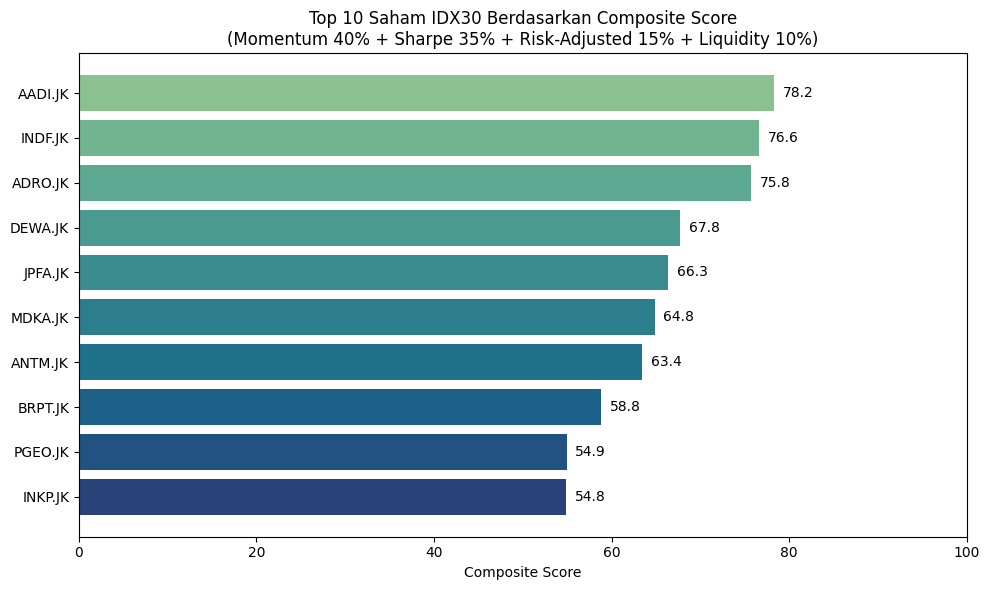

In [24]:
top10 = final_ranking.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette("crest", len(top10))[::-1]

bars = ax.barh(top10.index[::-1], top10['composite_score'][::-1], color=colors)
ax.set_xlabel('Composite Score')
ax.set_title('Top 10 Saham IDX30 Berdasarkan Composite Score\n(Momentum 40% + Sharpe 35% + Risk-Adjusted 15% + Liquidity 10%)')
ax.set_xlim(0, 100)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}', va='center')

plt.tight_layout()
plt.show()

### Heatmap Korelasi Antar Saham

Korelasi dihitung dari daily returns, bukan harga langsung (harga saham cenderung selalu naik seiring waktu sehingga korelasinya bias tinggi kalau dihitung dari harga; return harian lebih mencerminkan pergerakan riil).

Insight ini berguna untuk diversifikasi portofolio saham dengan korelasi tinggi bergerak searah, jadi kurang efektif untuk mengurangi risiko kalau dipegang bersamaan.

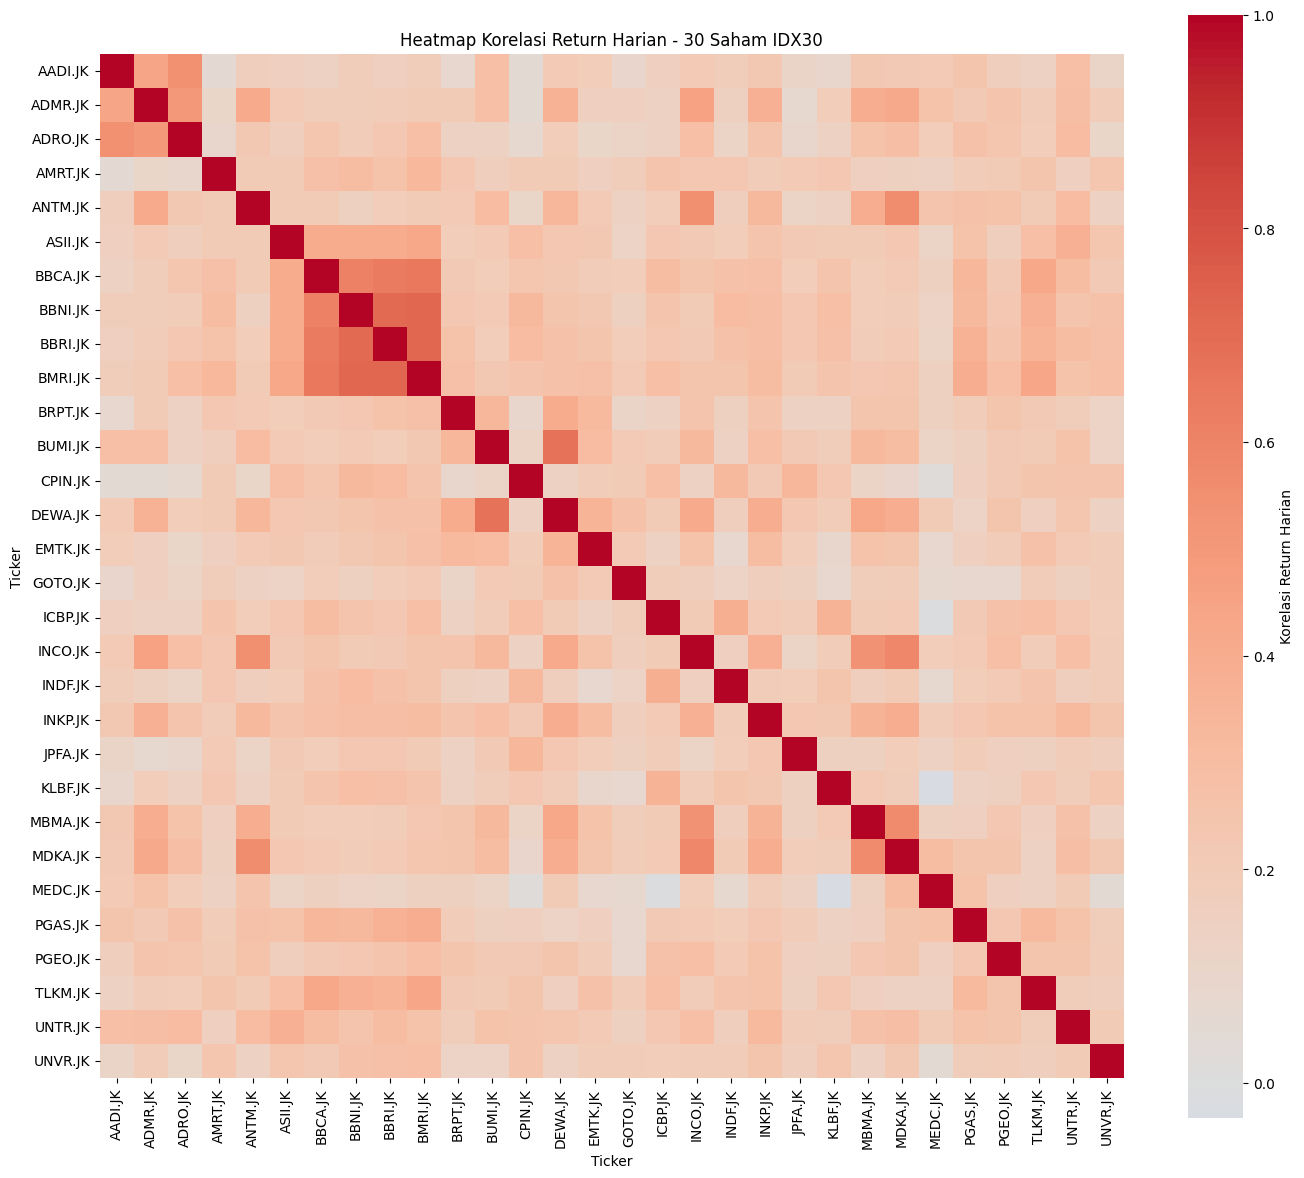

In [25]:
correlation_matrix = daily_returns.corr()

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    annot=False,
    square=True,
    cbar_kws={'label': 'Korelasi Return Harian'},
    ax=ax
)
ax.set_title('Heatmap Korelasi Return Harian - 30 Saham IDX30')
plt.tight_layout()
plt.show()

## 6. Sensitivity Analysis — Uji Kestabilan Bobot

Bobot komposit (Momentum 40%, Sharpe 35%, Risk-Adjusted 15%, Liquidity 10%) adalah keputusan subjektif kita. Untuk menguji seberapa robust ranking ini, kita coba beberapa skema bobot alternatif dan lihat:

1. Apakah top 5 saham tetap konsisten di berbagai skema bobot?
2. Saham mana yang rankingnya paling stabil (selalu di posisi tinggi) vs paling sensitif (naik-turun drastis tergantung bobot)?

Skema yang diuji:
- **Base case**: Momentum 40% / Sharpe 35% / Risk 15% / Liquidity 10% (skema awal kita)
- **Momentum-heavy**: 60% / 20% / 10% / 10% (lebih agresif ke tren harga)
- **Risk-averse**: 20% / 30% / 40% / 10% (lebih konservatif, prioritas ke stabilitas)
- **Equal-weight**: 25% / 25% / 25% / 25% (semua kategori setara, tanpa preferensi)

In [26]:
weight_schemes = {
    'Base Case (40/35/15/10)': {'momentum': 0.40, 'sharpe': 0.35, 'risk': 0.15, 'liquidity': 0.10},
    'Momentum-Heavy (60/20/10/10)': {'momentum': 0.60, 'sharpe': 0.20, 'risk': 0.10, 'liquidity': 0.10},
    'Risk-Averse (20/30/40/10)': {'momentum': 0.20, 'sharpe': 0.30, 'risk': 0.40, 'liquidity': 0.10},
    'Equal-Weight (25/25/25/25)': {'momentum': 0.25, 'sharpe': 0.25, 'risk': 0.25, 'liquidity': 0.25},
}

sensitivity_results = pd.DataFrame(index=scores.index)

for scheme_name, w in weight_schemes.items():
    composite = (
        scores['momentum_score'] * w['momentum'] +
        scores['sharpe_score'] * w['sharpe'] +
        scores['risk_adjusted_score'] * w['risk'] +
        scores['liquidity_score'] * w['liquidity']
    )
    sensitivity_results[scheme_name] = composite.round(2)

# Ranking per skema (1 = terbaik)
sensitivity_rank = sensitivity_results.rank(ascending=False).astype(int)

print("=== Composite Score per Skema Bobot ===")
display(sensitivity_results.sort_values('Base Case (40/35/15/10)', ascending=False))

print("\n=== Ranking (1 = terbaik) per Skema Bobot ===")
display(sensitivity_rank.sort_values('Base Case (40/35/15/10)'))

=== Composite Score per Skema Bobot ===


,Base Case (40/35/15/10),Momentum-Heavy (60/20/10/10),Risk-Averse (20/30/40/10),Equal-Weight (25/25/25/25)
Ticker,,,,
AADI.JK,78.2500,81.5000,66.0000,62.5000
INDF.JK,76.5800,81.1700,79.0000,68.3300
ADRO.JK,75.7500,76.8400,71.6700,70.0000
DEWA.JK,67.7500,63.8400,52.6700,63.7500
JPFA.JK,66.3300,61.0000,69.0000,60.0000
MDKA.JK,64.8400,70.3400,49.3400,57.0800
ANTM.JK,63.4200,54.8300,61.0000,62.9200
BRPT.JK,58.8300,56.0000,46.3300,56.6700
PGEO.JK,54.9200,64.8300,46.6700,47.5000



=== Ranking (1 = terbaik) per Skema Bobot ===


,Base Case (40/35/15/10),Momentum-Heavy (60/20/10/10),Risk-Averse (20/30/40/10),Equal-Weight (25/25/25/25)
Ticker,,,,
AADI.JK,1,1,4,5
INDF.JK,2,2,1,2
ADRO.JK,3,3,2,1
DEWA.JK,4,7,13,3
JPFA.JK,5,8,3,8
MDKA.JK,6,4,17,11
ANTM.JK,7,16,5,4
BRPT.JK,8,14,21,13
PGEO.JK,9,5,20,18


In [27]:
# Cek konsistensi Top 5 di setiap skema
print("Top 5 saham per skema bobot:\n")
for scheme_name in weight_schemes.keys():
    top5 = sensitivity_results[scheme_name].sort_values(ascending=False).head(5)
    print(f"{scheme_name}:")
    print(f"  {list(top5.index)}\n")

# Saham yang konsisten muncul di Top 5 di SEMUA skema
top5_sets = [set(sensitivity_results[s].sort_values(ascending=False).head(5).index) for s in weight_schemes.keys()]
consistently_top5 = set.intersection(*top5_sets)
print(f"Saham yang konsisten Top 5 di SEMUA skema bobot: {consistently_top5}")

Top 5 saham per skema bobot:

Base Case (40/35/15/10):
  ['AADI.JK', 'INDF.JK', 'ADRO.JK', 'DEWA.JK', 'JPFA.JK']

Momentum-Heavy (60/20/10/10):
  ['AADI.JK', 'INDF.JK', 'ADRO.JK', 'MDKA.JK', 'PGEO.JK']

Risk-Averse (20/30/40/10):
  ['INDF.JK', 'ADRO.JK', 'JPFA.JK', 'AADI.JK', 'ANTM.JK']

Equal-Weight (25/25/25/25):
  ['ADRO.JK', 'INDF.JK', 'DEWA.JK', 'ANTM.JK', 'AADI.JK']

Saham yang konsisten Top 5 di SEMUA skema bobot: {'AADI.JK', 'ADRO.JK', 'INDF.JK'}


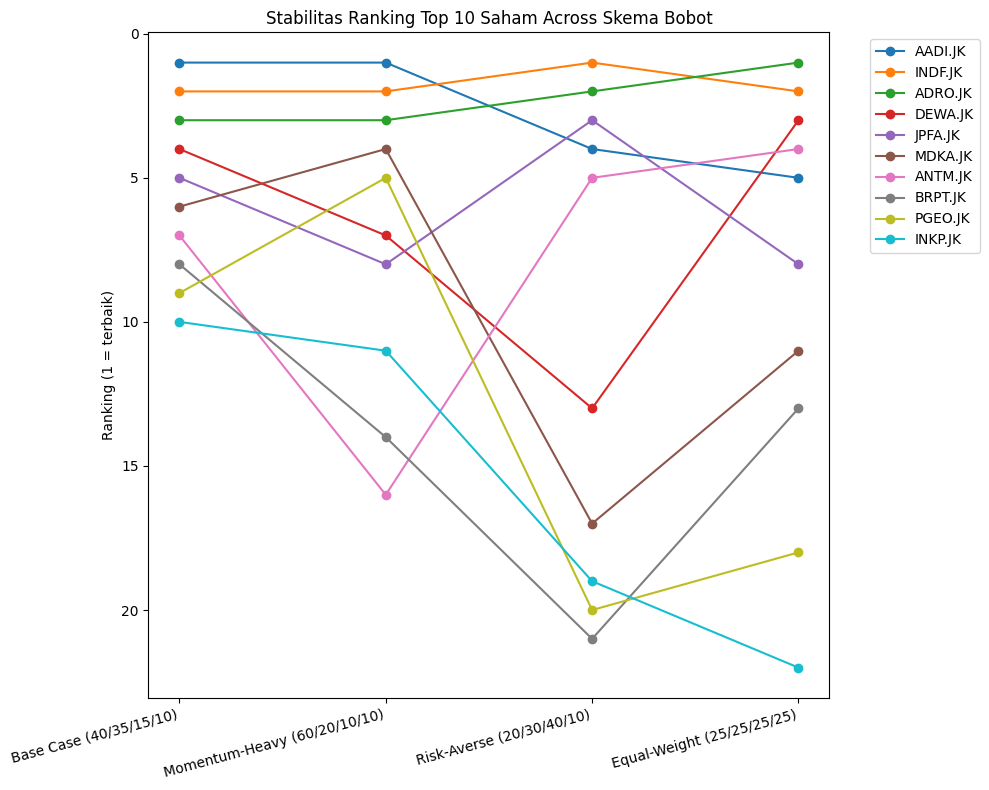

In [28]:
fig, ax = plt.subplots(figsize=(10, 8))
top10_tickers = sensitivity_rank.sort_values('Base Case (40/35/15/10)').head(10).index

for ticker in top10_tickers:
    ax.plot(list(weight_schemes.keys()), sensitivity_rank.loc[ticker], marker='o', label=ticker)

ax.invert_yaxis()  # ranking 1 di atas
ax.set_ylabel('Ranking (1 = terbaik)')
ax.set_title('Stabilitas Ranking Top 10 Saham Across Skema Bobot')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

## 7. Insight & Kesimpulan

### Ringkasan Hasil

Berdasarkan composite score (Momentum 40% + Sharpe Ratio 35% + Risk-Adjusted 15% + Liquidity 10%), 5 saham teratas dari 30 konstituen IDX30 (periode Agustus 2026) adalah:

1. **AADI.JK (78.2)** — unggul di momentum dan sharpe ratio, namun liquidity relatif rendah
2. **INDF.JK (76.6)** — saham paling defensif dari sisi risiko (skor volatility & drawdown tertinggi di IDX30), dengan momentum kuat, namun kurang likuid
3. **ADRO.JK (75.8)** — kombinasi seimbang antara momentum tinggi, sharpe ratio baik, dan drawdown yang terkendali
4. **DEWA.JK (67.8)** — sharpe ratio tertinggi di seluruh IDX30 namun volatility & drawdown terburuk — profil high risk, high reward
5. **JPFA.JK (66.3)** — sharpe ratio dan drawdown baik, momentum moderat

### Robustness Ranking (Sensitivity Analysis)

Untuk menguji apakah ranking di atas hanya artefak dari bobot komposit yang subjektif, dilakukan sensitivity analysis dengan 4 skema bobot berbeda (Base Case, Momentum-Heavy, Risk-Averse, Equal-Weight). Hasilnya:

- **AADI.JK, ADRO.JK, dan INDF.JK konsisten masuk top 5 di keempat skema**, termasuk pada dua skema dengan filosofi berlawanan (Momentum-Heavy vs Risk-Averse). Ini mengindikasikan bahwa ketiga saham ini unggul secara robust, bukan hasil pemilihan bobot yang menguntungkan mereka secara spesifik.
- **DEWA.JK menunjukkan volatilitas ranking tinggi** — top 5 di Base Case dan Momentum-Heavy, namun jatuh ke ranking 13 di skema Risk-Averse. Ini konsisten dengan profil high-risk-nya: menarik untuk investor agresif, namun tidak solid untuk profil konservatif.
- Saham **CPIN.JK, KLBF.JK, dan EMTK.JK secara konsisten berada di 5 terbawah** di semua skema, menunjukkan kelemahan yang bukan disebabkan oleh bias pembobotan.

### Insight Diversifikasi

Heatmap korelasi menunjukkan klaster korelasi tinggi pada saham-saham perbankan besar (BBCA, BBNI, BBRI, BMRI), yang mengindikasikan pergerakan harga mereka cenderung serempak. Ini artinya memegang beberapa saham bank sekaligus tidak memberi manfaat diversifikasi yang signifikan; portofolio yang lebih tahan risiko sebaiknya menggabungkan saham dari sektor yang korelasinya rendah satu sama lain.

### Limitasi Screener

- **Backward-looking**: seluruh metrik dihitung dari data historis 2 tahun terakhir, tidak menjamin performa yang sama akan berlanjut ke depan
- **Tidak mempertimbangkan fundamental**: screener ini murni berbasis harga & volume, tidak memasukkan rasio keuangan seperti PER, PBV, ROE, atau kesehatan laporan keuangan perusahaan
- **Tidak mempertimbangkan faktor makro/sentimen**: berita, kebijakan pemerintah, kondisi ekonomi global tidak masuk dalam perhitungan
- **Bobot dasar bersifat subjektif**, meski sudah divalidasi lewat sensitivity analysis — skema bobot lain di luar 4 yang diuji masih mungkin menghasilkan ranking berbeda
- **Data saham baru listing (AADI)**: memiliki histori data lebih pendek dibanding saham lain, sehingga perhitungan metriknya kurang seimbang dibandingkan saham yang sudah listing penuh 2 tahun

### Potensi Pengembangan Lanjutan

Screener ini bisa menjadi tahap awal (initial filter) sebelum dilakukan analisis fundamental lebih mendalam pada saham-saham yang lolos, atau digabungkan dengan backtest strategi teknikal sederhana untuk menguji apakah saham-saham top hasil screening benar-benar menghasilkan return yang lebih baik jika diperdagangkan secara aktif.